# [1] 03 Cross-fault creep time series

```
Created on Wed Sep 23 2026
@author: daniellelindsay
Run in opera_disp_feb13. ~15 min per track for the time-series read, the rest seconds.
```

**The method.** At every 100 m crossing of the mapped Hayward trace:

1. take the InSAR pixels in a box perpendicular to the LOCAL strike:
   within `x_width` along the fault and between `dist_min` and `dist_max`
   from the trace, on each side (`w_subset`, `e_subset`)
2. median of the west pixels and median of the east pixels at every date
   (`w_avg`, `e_avg`)
3. `west_east_ts = e_avg - w_avg`, in LOS mm

That is the whole thing (Old_WD2TB_PhD/Scripts/fault_creeprate_itterate_segments.py
and the AGU_extract_creep_rates_*.py scripts). The difference cancels the
reference datum and the per-date common-mode noise (Methods M3). It is done
separately for the ascending (09157) and descending (11115) frames.

**The four additions the paper needs**, each in its own section below:

- a per-pixel RATE MASK: a pixel whose LOS rate is > 3 robust sigma from the
  median rate of ITS OWN SIDE at that crossing is a landslide, quarry or edge
  and is dropped (Fig S3)
- a COMMON DATE GRID: each track interpolated onto the union of dates, only
  across gaps shorter than 45 days (Fig S4)
- the asc + desc DECOMPOSITION into fault-parallel (FP) and vertical (Up)
  with the local strike; `fp_ts.csv` is THE input to 04, 05 and 08
- a crossing-level LANDSLIDE FLAG: a crossing whose FP rate is > 3 robust
  sigma from a 21-crossing running median is dropped from every product

**Geometry** (definitions from MintPy `utils0.enu2los`; check there, not here):

```
inc_angle  - incidence angle of the LOS vector, measured from vertical
az_angle   - azimuth of the LOS vector FROM THE GROUND TO THE SATELLITE, measured
             from north, ANTI-CLOCKWISE positive.  head_angle = 90 - az_angle.
             Ours: ascending  ~100 (flies N10W, looks east, sits WEST of the pixel)
                   descending ~260 (flies S10E, looks west, sits EAST of the pixel)
profile_az - the cross-fault direction of each crossing, compass bearing clockwise
             from north, pointing to the EAST side (~54).  strike = profile_az + 90 (~144, SE)
```

**Outputs** (`outputs/03_creep_timeseries/`):
- per track: `creep_ts_LOS_<track>.csv` (lat x decimal-year matrix, mm LOS),
  `creep_geom_<track>.csv` (mean incidence / azimuth per crossing),
  `creep_params_<track>.json`, `rate_deviation_<track>.csv`
- common grid: `asc_los_interp.csv`, `desc_los_interp.csv`, `fp_ts.csv`, `up_ts.csv`
- along-fault rates: `creep_rate_fp.csv`, `creep_rate_up.csv`; `decompose_params.json`
- `03_creep_stats.txt` and the registry rows `03_*`

**Figures**: S3 (the rate mask), S4 (real versus interpolated epochs), a QC
plot of the trace azimuth and one of the along-fault creep rate.

**What to check when you run it.** Rate-mask sigma ~0.56 mm/yr on both tracks,
~6 % of pixels rejected; 423 common dates, 277 with both tracks real; median
FP creep rate ~4.7 mm/yr and CFW1's crossing ~6.8 mm/yr. The CHECK cells
compare every product with the previous run of this notebook.

In [1]:
# [2]
import os
import json

import insar_utils as utils
from TulePond_filepaths import (common_paths, insar_dic_list, creepmeters, unit, params,
                                dist_min, dist_max, x_width, min_points, coh_timeseries,
                                rate_nsigma, az_smooth_n, max_interp_gap_days, rate_smooth_km,
                                paths_out, repo_dir)

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import h5py                                      # MintPy HDF5 products
from pyproj import Transformer                   # lon/lat -> UTM
from scipy.ndimage import gaussian_filter1d      # along-fault smoothing
import matplotlib.pyplot as plt

## [3] Paths and parameters

The aperture, mask and smoothing choices come from `TulePond_filepaths.py`
so every notebook uses the same values (reasons in the assumptions
register). The few below are used only here.

In [2]:
# [4]
notebook = "03_creep_timeseries"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# the products of the previous version of this notebook, for the CHECK cells

utm_epsg = 32610         # UTM 10N, the grid the frames live on
# The square of pixels read around each crossing. This is NOT a selection: the pixels used are
# picked by p and q (dist_min to dist_max across, x_width along) and any window that contains
# that box gives the same answer. It only has to be big enough: the box corners are
# hypot(dist_max, x_width) = 250 m from the crossing, so 10 pixels (300 m) each way. Reading
# 21 x 21 pixels per crossing instead of the whole 3048 x 2333 frame is what makes the 13 GB
# cube usable.
win_pix = int(np.ceil(np.hypot(dist_max, x_width) * 1000 / 30.0)) + 1
lat_min = 37.489475      # southern cutoff: below it the data are too patchy and the fault splays
trend_window = 21        # crossings (~2 km) in the running median used to flag landslide crossings
trend_nsigma = 3.0       # a crossing whose FP rate departs from that trend by more than this is dropped
s1b_death = 2021.98      # Sentinel-1B failed 2021-12-23: 6-day sampling ends (Fig S4)

print(f"aperture {dist_min * 1000:.0f}-{dist_max * 1000:.0f} m, along-strike +/-{x_width * 1000:.0f} m, "
      f"min {min_points} px per side, coherence {coh_timeseries}, rate mask {rate_nsigma:g} sigma")
print("tracks: " + ", ".join(f"{d['ORBIT_DIRECTION']} {d['Frame']}" for d in insar_dic_list))

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(*[d[k] for d in insar_dic_list for k in ("ts_file", "vel_file", "geo_file")],
           *[d["mask_file"][coh_timeseries] for d in insar_dic_list],
           common_paths["fault_profiles"])

aperture 30-150 m, along-strike +/-200 m, min 5 px per side, coherence 0.7, rate mask 3 sigma
tracks: ascending 09157, descending 11115
Registry for 03_creep_timeseries: run 47f6354a, git 5952336+


## [5] Fault trace

`hayward_fault_profiles.csv` is the mapped trace resampled every 100 m
(built in notebook 01 from the KML): `ft_lon, ft_lat, profile_az`, south to
north, `profile_az` the cross-fault azimuth pointing to the east side.

The raw azimuth carries the 100 m jitter of hand digitising (a few kinks of
10-20 degrees). A 21-crossing (2.1 km) rolling median removes the kinks and
keeps the real bends of the trace; the same smoothing is used in notebook 02.
At Tule Pond it changes the band rates by ~0.2 mm/yr and the event steps by
~0.1 mm and does not move the section ends (checked 2026-09-23).

791 crossings from 37.4141 N (south, 79.0 km) to 37.9915 N (Point Pinole, 0 km)
cross-fault azimuth: raw 23.7 to 76.4, smoothed 45.8 to 68.2 deg; |raw - smoothed| > 10 deg at 26 crossings


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


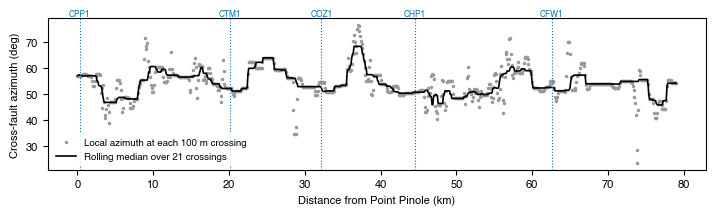

In [3]:
# [6]
x_fault = pd.read_csv(common_paths["fault_profiles"])
x_fault["az_smooth"] = x_fault["profile_az"].rolling(az_smooth_n, center=True, min_periods=3).median()
km_of = utils.lat_to_km_map(common_paths["fault_profiles"])      # lat -> km from Point Pinole
x_fault["km"] = km_of(x_fault["ft_lat"].values)

# UTM position of every crossing, for the pixel windows
ll2utm = Transformer.from_crs("EPSG:4326", f"EPSG:{utm_epsg}", always_xy=True)
x_fault["easting"], x_fault["northing"] = ll2utm.transform(x_fault["ft_lon"].values, x_fault["ft_lat"].values)

print(f"{len(x_fault)} crossings from {x_fault.ft_lat.min():.4f} N (south, {x_fault.km.max():.1f} km) "
      f"to {x_fault.ft_lat.max():.4f} N (Point Pinole, 0 km)")
print(f"cross-fault azimuth: raw {x_fault.profile_az.min():.1f} to {x_fault.profile_az.max():.1f}, "
      f"smoothed {x_fault.az_smooth.min():.1f} to {x_fault.az_smooth.max():.1f} deg; "
      f"|raw - smoothed| > 10 deg at {(np.abs(x_fault.profile_az - x_fault.az_smooth) > 10).sum()} crossings")

utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
fig, ax = plt.subplots(figsize=(7.2, 2.2))
ax.plot(x_fault.km, x_fault.profile_az, ".", color="0.6", ms=3, label="Local azimuth at each 100 m crossing")
ax.plot(x_fault.km, x_fault.az_smooth, "-", color="k", lw=1.2, label=f"Rolling median over {az_smooth_n} crossings")
for code, la, lo, name in creepmeters:
    ax.axvline(km_of([la])[0], color="#0072B2", lw=0.8, ls=":")
    ax.text(km_of([la])[0], ax.get_ylim()[1], code, ha="center", va="bottom", fontsize=6, color="#0072B2")
ax.set_xlabel("Distance from Point Pinole (km)")
ax.set_ylabel("Cross-fault azimuth (deg)")
ax.legend(fontsize=7)
fig.tight_layout()
f_qc = os.path.join(fig_dir, f"qc03_profile_azimuth_smooth{az_smooth_n}.png"); fig.savefig(f_qc, dpi=300); fig.savefig(f_qc.replace(".png", ".pdf"))
plt.show()

## [7] Functions

Only what is used for both tracks. `get_fault_pairs` is unchanged from the
2025 scripts. `get_window_points` replaces the `pygmt.project` call of those
scripts: it returns the same `p` (across the fault, positive to the east
side) and `q` (along the fault) in km, computed in UTM inside a small pixel
window instead of on the whole frame, because the displacement cube is 13 GB
per track and is read one window at a time. At the CFW1 crossing the two
routes pick the same pixels (checked 2026-09-23).

In [4]:
# [8]
def read_insar_data(dic):
    """Geometry, coherence mask, velocity (mm/yr), dates and the grid of one
    track. The displacement cube is NOT loaded: `ts` is the open h5py dataset
    and is read per crossing window. Close `ts_h5` when done."""
    print(f"Loading {dic['ORBIT_DIRECTION']} {dic['Frame']}")
    with h5py.File(dic["geo_file"], "r") as hf:
        inc = hf["incidenceAngle"][:].astype(np.float64)     # stored float16; cast before any arithmetic
        azi = hf["azimuthAngle"][:].astype(np.float64)
    with h5py.File(dic["mask_file"][coh_timeseries], "r") as hf:
        mask = hf["mask"][:].astype(bool)
    with h5py.File(dic["vel_file"], "r") as hf:
        vel = hf["velocity"][:].astype(np.float64) * unit     # mm/yr, the rate-mask discriminator
    ts_h5 = h5py.File(dic["ts_file"], "r")
    attrs = ts_h5.attrs
    ts_dates = np.array([utils.date_to_decimal_year(d.decode()) for d in ts_h5["date"][:]])
    x_step, y_step = float(attrs["X_STEP"]), float(attrs["Y_STEP"])
    print(f"   cube {ts_h5['timeseries'].shape} (dates x rows x cols), {x_step:.0f} m grid, "
          f"coherence-{coh_timeseries} mask keeps {100 * mask.mean():.1f}% of pixels")
    return {"inc": inc, "azi": azi, "mask": mask, "vel": vel,
            "ts_h5": ts_h5, "ts": ts_h5["timeseries"], "ts_dates": ts_dates,
            "x_first": float(attrs["X_FIRST"]), "y_first": float(attrs["Y_FIRST"]),
            "x_step": x_step, "y_step": y_step, "length": inc.shape[0], "width": inc.shape[1],
            "win": max(win_pix, int(np.ceil(np.hypot(dist_max, x_width) * 1000.0 / abs(x_step))) + 1)}


def get_window_points(insar, easting_0, northing_0, az):
    """The coherent pixels in a square window around one crossing, as a table:
    row, col (pixel), p = signed distance across the fault (km, + toward az,
    the east side), q = distance along the fault (km), vel, inc, azi.
    Pixels further than x_width along the fault are dropped. None if the
    crossing is off the frame."""
    # The frame is a regular UTM grid: pixel (row, col) sits at
    #     easting  = x_first + col * x_step        (x_step = +30 m, col 0 is the west edge)
    #     northing = y_first + row * y_step        (y_step = -30 m, row 0 is the north edge)
    # so the pixel under the crossing is found by inverting that.
    col_centre = int(round((easting_0 - insar["x_first"]) / insar["x_step"]))
    row_centre = int(round((northing_0 - insar["y_first"]) / insar["y_step"]))
    # The square of +/- win pixels around it (300 m, enough to hold the whole dist_max x x_width
    # box whatever its orientation), clipped at the frame edge. Nothing is selected here; the
    # selection is the p, q filter below and get_fault_pairs. Fewer than 3 pixels a side means
    # the crossing is off the frame.
    row_min, row_max = max(0, row_centre - insar["win"]), min(insar["length"], row_centre + insar["win"] + 1)
    col_min, col_max = max(0, col_centre - insar["win"]), min(insar["width"], col_centre + insar["win"] + 1)
    if row_max - row_min < 3 or col_max - col_min < 3:
        return None
    # easting and northing of every pixel in the window, then the pygmt.project step: the
    # distance of each pixel from the crossing along the cross-fault azimuth (p) and along the fault (q)
    cols, rows = np.meshgrid(np.arange(col_min, col_max), np.arange(row_min, row_max))
    easting = insar["x_first"] + cols * insar["x_step"]
    northing = insar["y_first"] + rows * insar["y_step"]
    az = np.deg2rad(az)
    p = ((easting - easting_0) * np.sin(az) + (northing - northing_0) * np.cos(az)) / 1000.0
    q = ((easting - easting_0) * np.sin(az + np.pi / 2) + (northing - northing_0) * np.cos(az + np.pi / 2)) / 1000.0
    points = pd.DataFrame({"row": rows.ravel(), "col": cols.ravel(), "p": p.ravel(), "q": q.ravel(),
                           "vel": insar["vel"][row_min:row_max, col_min:col_max].ravel(),
                           "inc": insar["inc"][row_min:row_max, col_min:col_max].ravel(),
                           "azi": insar["azi"][row_min:row_max, col_min:col_max].ravel(),
                           "coherent": insar["mask"][row_min:row_max, col_min:col_max].ravel()})
    points = points[points.coherent & np.isfinite(points.vel) & (np.abs(points.q) <= x_width)]
    return points


def get_fault_pairs(points, dist_min, dist_max):
    w_subset = points[(points.p > -dist_max) & (points.p < -dist_min)]
    e_subset = points[(points.p > dist_min) & (points.p < dist_max)]
    return w_subset, e_subset


def read_creep_ts(path):
    """A lat x decimal-year csv back as a DataFrame with float index and columns."""
    df = pd.read_csv(path, index_col=0)
    df.columns = df.columns.astype(float)
    df.index = df.index.astype(float)
    return df

## [9] Extract the cross-fault time series, one track at a time

Two loops over the crossings per track.

**Loop 1: the pixel pairs and the rate mask.** At every crossing take the
window, split it into `w_subset` and `e_subset`, and note every pixel's LOS
rate as its deviation from the median rate of ITS OWN side. Fault creep is a
difference BETWEEN sides so it does not enter, and the pooled deviations are
centred on zero along the whole fault. One robust sigma per track sets the
cut.

**Loop 2: the difference.** Drop the pixels beyond the cut, read the
displacement cube in the crossing's window, median each side per date, and
difference east minus west. The mean incidence and azimuth of the pixels
used are kept for the decomposition.

The cube read takes ~15 min per track, so if the per-track files are already
on disk with the same parameters the track is skipped and the mask numbers
are recomputed from the saved deviations. Delete the files, or change a
parameter, to force a re-run.

In [5]:
# [10]
params_now = dict(coh=coh_timeseries, dist_min=dist_min, dist_max=dist_max, x_width=x_width,
                  min_points=min_points, rate_nsigma=rate_nsigma)

def ts_data_key(dic):
    """Identity of this track's input time series, for the reuse test below.

    The test has to include the DATA, not only the parameters. A data refresh
    adds epochs to timeseries_tropo.h5 while every parameter stays the same, so
    keying on parameters alone silently reused the previous extraction: on
    2026-09-28 the March-2026 run rebuilt fp_ts.csv from September LOS series
    and every product downstream inherited the old dates.
    """
    with h5py.File(dic["ts_file"], "r") as h:
        d = h["date"][:]
    return dict(n_dates=len(d), first_date=d[0].decode(), last_date=d[-1].decode())

mask_stats = {}

for dic in insar_dic_list:
    track = dic["ORBIT_DIRECTION"]
    ts_file = os.path.join(out_dir, f"creep_ts_LOS_{track}.csv")
    geom_file = os.path.join(out_dir, f"creep_geom_{track}.csv")
    params_file = os.path.join(out_dir, f"creep_params_{track}.json")
    dev_file = os.path.join(out_dir, f"rate_deviation_{track}.csv")

    # ---------- already on disk with these parameters? then only the mask numbers
    cache_key = {**params_now, **ts_data_key(dic)}
    if os.path.exists(params_file) and json.load(open(params_file)) == cache_key and os.path.exists(ts_file):
        print(f"[{track}] extraction already on disk with these parameters; reusing")
        rate_dev = pd.read_csv(dev_file)["rate_deviation_mm_yr"].to_numpy()
        creep_ts = read_creep_ts(ts_file)
        sigma = utils.robust_sigma(rate_dev)
        rate_cut = rate_nsigma * sigma
        mask_stats[track] = dict(track=track, n_crossings=len(creep_ts), n_dates=creep_ts.shape[1],
                                 ts_dates=creep_ts.columns.to_numpy(), sigma=sigma, rate_cut=rate_cut,
                                 rej_pct=100.0 * np.mean(np.abs(rate_dev) > rate_cut), n_px=rate_dev.size,
                                 max_dev=float(np.abs(rate_dev).max()), n_dropped=np.nan)
        continue

    insar = read_insar_data(dic)

    # ---------- Loop 1: pixel pairs at every crossing, rate deviation of every pixel from its own side
    print(f"[{track}] loop 1: pixel pairs and rate deviations ...")
    pairs = {}                  # index in x_fault -> (w_subset, e_subset)
    rate_dev = []
    for index, row in x_fault.iterrows():
        points = get_window_points(insar, row["easting"], row["northing"], row["az_smooth"])
        if points is None:
            continue
        w_subset, e_subset = get_fault_pairs(points, dist_min, dist_max)
        if len(w_subset) < min_points or len(e_subset) < min_points:
            continue
        pairs[index] = (w_subset, e_subset)
        rate_dev.append(w_subset["vel"] - w_subset["vel"].median())
        rate_dev.append(e_subset["vel"] - e_subset["vel"].median())
    rate_dev = pd.concat(rate_dev).to_numpy()
    sigma = utils.robust_sigma(rate_dev)
    rate_cut = rate_nsigma * sigma

    # ---------- Loop 2: drop the fast pixels, read the cube, median each side, east - west
    print(f"[{track}] loop 2: reading the cube at {len(pairs)} crossings ...")
    creep_ts = {}               # ft_lat -> east - west LOS (mm) at every date
    geometry = {}               # ft_lat -> (mean inc, mean azi) of the pixels used
    n_rejected = n_total = n_dropped = 0
    for index, (w_subset, e_subset) in pairs.items():
        w_keep = w_subset[np.abs(w_subset["vel"] - w_subset["vel"].median()) <= rate_cut]
        e_keep = e_subset[np.abs(e_subset["vel"] - e_subset["vel"].median()) <= rate_cut]
        n_total += len(w_subset) + len(e_subset)
        n_rejected += (len(w_subset) - len(w_keep)) + (len(e_subset) - len(e_keep))
        if len(w_keep) < min_points or len(e_keep) < min_points:
            n_dropped += 1
            continue
        # the smallest box holding both sides, read from the cube in one go (m -> mm)
        both = pd.concat([w_keep, e_keep]).sort_values(["row", "col"])
        r_min, r_max = both["row"].min(), both["row"].max() + 1
        c_min, c_max = both["col"].min(), both["col"].max() + 1
        ts_win = insar["ts"][:, r_min:r_max, c_min:c_max] * unit
        w_avg = np.nanmedian(ts_win[:, (w_keep["row"] - r_min).to_numpy(), (w_keep["col"] - c_min).to_numpy()], axis=1)
        e_avg = np.nanmedian(ts_win[:, (e_keep["row"] - r_min).to_numpy(), (e_keep["col"] - c_min).to_numpy()], axis=1)
        west_east_ts = e_avg - w_avg
        ft_lat = float(x_fault.loc[index, "ft_lat"])
        creep_ts[ft_lat] = west_east_ts
        geometry[ft_lat] = (float(np.nanmean(both["inc"])), float(np.nanmean(both["azi"])))
    insar["ts_h5"].close()

    # ---------- save: lat x decimal-year matrix (rows south -> north), geometry, parameters, deviations
    creep_ts = pd.DataFrame.from_dict(creep_ts, orient="index", columns=np.round(insar["ts_dates"], 4))
    creep_ts.index.name = "lat"
    creep_ts.sort_index().to_csv(ts_file)
    geometry = pd.DataFrame.from_dict(geometry, orient="index", columns=["inc_deg", "azi_deg"])
    geometry.index.name = "lat"
    geometry.sort_index().to_csv(geom_file)
    with open(params_file, "w") as fh:
        json.dump({**params_now, **ts_data_key(dic)}, fh, indent=1)
    pd.DataFrame({"rate_deviation_mm_yr": rate_dev}).to_csv(dev_file, index=False)

    rej_pct = 100.0 * n_rejected / n_total
    print(f"[{track}] {len(creep_ts)}/{len(x_fault)} crossings, {len(insar['ts_dates'])} dates")
    print(f"          rate mask: sigma {sigma:.3f} mm/yr, cut +/-{rate_cut:.3f} ({rate_nsigma:g} sigma) -> "
          f"{rej_pct:.1f}% of pixels rejected, {n_dropped} crossings dropped, max |dev| {np.abs(rate_dev).max():.1f}")
    print("")
    mask_stats[track] = dict(track=track, n_crossings=len(creep_ts), n_dates=len(insar["ts_dates"]),
                             ts_dates=insar["ts_dates"], sigma=sigma, rate_cut=rate_cut, rej_pct=rej_pct,
                             n_px=rate_dev.size, max_dev=float(np.abs(rate_dev).max()), n_dropped=n_dropped)

[ascending] extraction already on disk with these parameters; reusing
[descending] extraction already on disk with these parameters; reusing


## [11] One crossing by hand

The crossing nearest CFW1 is redone at the last epoch in four lines, so
the median difference is visible without the loop.

In [6]:
# [12]
dic = insar_dic_list[0]                                                    # ascending
cfw1_lat = [c[1] for c in creepmeters if c[0] == "CFW1"][0]
row = x_fault.loc[(x_fault.ft_lat - cfw1_lat).abs().idxmin()]
insar = read_insar_data(dic)
points = get_window_points(insar, row["easting"], row["northing"], row["az_smooth"])
w_subset, e_subset = get_fault_pairs(points, dist_min, dist_max)
last = insar["ts"][-1] * unit                                              # the last epoch, whole frame, mm
insar["ts_h5"].close()
by_hand = (np.nanmedian(last[e_subset["row"].to_numpy(), e_subset["col"].to_numpy()])
           - np.nanmedian(last[w_subset["row"].to_numpy(), w_subset["col"].to_numpy()]))
from_file = read_creep_ts(os.path.join(out_dir, "creep_ts_LOS_ascending.csv")).loc[row["ft_lat"]].iloc[-1]
print(f"crossing nearest CFW1 at {row.ft_lat:.4f} N ({row.km:.1f} km), ascending, last epoch:")
print(f"   {len(w_subset)} west px, {len(e_subset)} east px before the rate mask")
print(f"   east median - west median by hand = {by_hand:.3f} mm;  in creep_ts_LOS_ascending.csv = {from_file:.3f} mm")
print("   (they differ only by the few pixels the rate mask removed)")
print(points.head())

Loading ascending 09157
   cube (359, 3048, 2333) (dates x rows x cols), 30 m grid, coherence-0.7 mask keeps 30.4% of pixels


crossing nearest CFW1 at 37.5321 N (62.6 km), ascending, last epoch:
   49 west px, 54 east px before the rate mask
   east median - west median by hand = -15.322 mm;  in creep_ts_LOS_ascending.csv = -15.450 mm
   (they differ only by the few pixels the rate mask removed)
     row   col         p         q       vel        inc        azi  coherent
13  2077  1612  0.254857 -0.192412 -2.217844  40.972431  99.867401      True
14  2077  1613  0.278657 -0.174149 -2.600508  40.972431  99.867401      True
15  2077  1614  0.302458 -0.155886 -2.241108  40.972431  99.867401      True
16  2077  1615  0.326258 -0.137623 -1.886170  40.972431  99.867401      True
17  2077  1616  0.350059 -0.119361 -1.742482  40.972431  99.867401      True


## [13] Figure S3: the rate mask

The pooled deviation population per track on a log count axis, with the
cut. The tail beyond the cut is what is rejected: landslides, quarries and
their edges. The core is kept whatever the local creep rate, because creep is
a difference between sides and never enters a within-side deviation.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-30/figS_ratemask_ap30-150m_coh0.7_mp5_sw200m_nsigma3.png


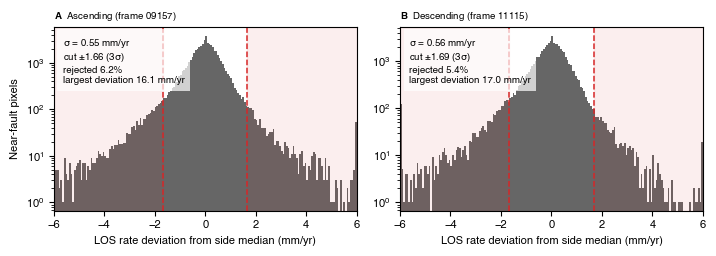

In [7]:
# [14]
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
lim, nbins = 6.0, 181
bins = np.linspace(-lim, lim, nbins)
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6))
for ax, dic, letter in zip(axes, insar_dic_list, "ab"):
    track = dic["ORBIT_DIRECTION"]
    stats = mask_stats[track]
    rate_dev = pd.read_csv(os.path.join(out_dir, f"rate_deviation_{track}.csv"))["rate_deviation_mm_yr"].to_numpy()
    ax.hist(np.clip(rate_dev, -lim, lim), bins=bins, color="0.4", log=True)     # clipped into the end bins, not dropped
    for sign in (-1, 1):
        ax.axvline(sign * stats["rate_cut"], color="tab:red", lw=1.1, ls="--")
    ax.axvspan(-lim, -stats["rate_cut"], color="tab:red", alpha=0.08)
    ax.axvspan(stats["rate_cut"], lim, color="tab:red", alpha=0.08)
    ax.set_xlim(-lim, lim)
    ax.set_xlabel("LOS rate deviation from side median (mm/yr)")
    utils.panel_title(ax, letter.upper(), f"{track.capitalize()} (frame {dic['Frame']})")
    ax.text(0.03, 0.95, f"$\\sigma$ = {stats['sigma']:.2f} mm/yr\ncut $\\pm${stats['rate_cut']:.2f} ({rate_nsigma:g}$\\sigma$)\n"
            f"rejected {stats['rej_pct']:.1f}%\nlargest deviation {stats['max_dev']:.1f} mm/yr",
            transform=ax.transAxes, va="top", ha="left", fontsize=7,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7))
axes[0].set_ylabel("Near-fault pixels")
fig.tight_layout()
figS3 = os.path.join(fig_dir, f"figS_ratemask_{params}_nsigma{rate_nsigma:g}.png")
fig.savefig(figS3, dpi=300)
fig.savefig(figS3.replace(".png", ".pdf"))
print("Saved figure to:", figS3)
plt.show()

## [15] Common date grid

The decomposition needs both tracks at the same epochs. Each crossing is
interpolated against its REAL acquisition dates onto the union of both
tracks' dates within their overlap, but only across gaps shorter than
`max_interp_gap_days` (45 d): that bridges the 6, 12 and 24 day sampling and
a few missed acquisitions, and leaves the two genuine 2018 ascending breaks
(72 and 84 d) as NaN. Nothing is extrapolated. Crossings south of `lat_min`
are dropped here.

In [8]:
# [16]
def interp_to_dates(target_dates, dates, values):
    """One crossing's series onto target_dates against its real dates. NaN
    inside gaps longer than max_interp_gap_days and outside the observed range."""
    out = np.full(len(target_dates), np.nan)
    ok = np.isfinite(values)
    if ok.sum() < 2:
        return out
    dates, values = dates[ok], values[ok]
    interp = np.interp(target_dates, dates, values)
    left = np.clip(np.searchsorted(dates, target_dates, side="right") - 1, 0, len(dates) - 1)   # real date at or before
    right = np.clip(left + 1, 0, len(dates) - 1)                                                # real date after
    is_real = np.isclose(target_dates, dates[left], atol=0.5 / 365.25)                          # a real acquisition
    gap_days = (dates[right] - dates[left]) * 365.25
    inside = (target_dates >= dates[0] - 0.5 / 365.25) & (target_dates <= dates[-1] + 0.5 / 365.25)
    keep = inside & (is_real | (gap_days <= max_interp_gap_days))
    out[keep] = interp[keep]
    return out


asc_los = read_creep_ts(os.path.join(out_dir, "creep_ts_LOS_ascending.csv"))
desc_los = read_creep_ts(os.path.join(out_dir, "creep_ts_LOS_descending.csv"))
t0 = max(asc_los.columns.min(), desc_los.columns.min())
t1 = min(asc_los.columns.max(), desc_los.columns.max())
common_dates = np.array(sorted(set(asc_los.columns) | set(desc_los.columns)))
common_dates = common_dates[(common_dates >= t0) & (common_dates <= t1)]
lats_all = np.array(sorted(set(asc_los.index) & set(desc_los.index)))
lats = lats_all[lats_all >= lat_min]
print(f"crossings on both tracks: {len(lats_all)}; south of {lat_min}: {len(lats_all) - len(lats)} dropped, {len(lats)} kept")

los_interp = {}
for name, los in (("asc", asc_los), ("desc", desc_los)):
    dates = los.columns.values.astype(float)
    matrix = np.full((len(lats), len(common_dates)), np.nan)
    for i, lat in enumerate(lats):
        matrix[i] = interp_to_dates(common_dates, dates, los.loc[lat].values)
    los_interp[name] = pd.DataFrame(matrix, index=lats, columns=common_dates)
    los_interp[name].index.name = "lat"
print(f"common grid: {len(lats)} crossings x {len(common_dates)} dates, {t0:.3f} to {t1:.3f}")

# which epochs are REAL on each track (an acquisition within half a day) and which are interpolated
real = {}
for name, los in (("asc", asc_los), ("desc", desc_los)):
    dates = los.columns.values.astype(float)
    real[name] = np.array([np.min(np.abs(dates - t)) < 0.5 / 365.25 for t in common_dates])
both_real = real["asc"] & real["desc"]
print(f"both tracks real at {both_real.sum()} epochs; interpolated: asc {(~real['asc']).sum()} "
      f"({100 * (~real['asc']).mean():.0f}%), desc {(~real['desc']).sum()} ({100 * (~real['desc']).mean():.0f}%)")

crossings on both tracks: 611; south of 37.489475: 1 dropped, 610 kept


common grid: 610 crossings x 439 dates, 2016.672 to 2026.216
both tracks real at 291 epochs; interpolated: asc 83 (19%), desc 65 (15%)


## [17] Decompose each crossing into fault-parallel and vertical

Per crossing, with the mean incidence and azimuth of the pixels used (one
pair per track) and the local strike (smoothed cross-fault azimuth + 90),
`utils.decompose_asc_desc` solves $[d_{asc}, d_{desc}]^T = G\,[U, FP]^T$ by
least squares at every epoch (the design matrix is pinned by the tests). FP
is positive along the strike bearing, so right-lateral creep is positive.

In [9]:
# [18]
geom = {}
for dic, key in zip(insar_dic_list, ("asc", "desc")):
    geometry = pd.read_csv(os.path.join(out_dir, f"creep_geom_{dic['ORBIT_DIRECTION']}.csv"), index_col=0)
    geom[key] = (float(geometry["inc_deg"].mean()), float(geometry["azi_deg"].mean()))
    print(f"{dic['ORBIT_DIRECTION']}: mean incidence {geom[key][0]:.2f}, mean azimuth {geom[key][1]:.2f} deg")

# local strike of every kept crossing: the smoothed cross-fault azimuth of the nearest trace point + 90
strike = np.array([x_fault["az_smooth"].values[np.argmin(np.abs(x_fault["ft_lat"].values - lat))] for lat in lats]) + 90.0

up_matrix = np.full((len(lats), len(common_dates)), np.nan)
fp_matrix = np.full((len(lats), len(common_dates)), np.nan)
for i, lat in enumerate(lats):
    d_asc, d_desc = los_interp["asc"].values[i], los_interp["desc"].values[i]
    ok = np.isfinite(d_asc) & np.isfinite(d_desc)
    if ok.sum() == 0:
        continue
    up_matrix[i, ok], fp_matrix[i, ok] = utils.decompose_asc_desc(
        d_asc[ok], d_desc[ok], geom["asc"][0], geom["asc"][1], geom["desc"][0], geom["desc"][1], strike[i])
up_ts = pd.DataFrame(up_matrix, index=lats, columns=common_dates)
fp_ts = pd.DataFrame(fp_matrix, index=lats, columns=common_dates)
up_ts.index.name = fp_ts.index.name = "lat"
print(f"decomposed {np.isfinite(fp_matrix).any(axis=1).sum()} crossings; G for a mid-fault crossing:")
print(utils.design_matrix_up_fp([geom["asc"][0], geom["desc"][0]], [geom["asc"][1], geom["desc"][1]],
                                float(np.median(strike))).round(3), "  (columns U, FP)")

ascending: mean incidence 40.26, mean azimuth 99.95 deg
descending: mean incidence 44.14, mean azimuth 260.54 deg
decomposed 610 crossings; G for a mid-fault crossing:
[[ 0.763 -0.285]
 [ 0.718  0.497]]   (columns U, FP)


## [19] Along-fault creep rate and the crossing-level landslide flag

A linear rate per crossing (`np.polyfit`, as in the 2025 scripts). The pixel
rate mask removes landslide EDGES, but a landslide that dominates one side IS
that side's median; such crossings stand out as spikes against the smooth
along-fault trend. Crossings more than `trend_nsigma` robust sigma from a
21-crossing running median are dropped from every product. The surviving
profile is smoothed with a 0.5 km Gaussian that preserves the gaps.

In [10]:
# [20]
def rate_per_crossing(ts):
    """Linear rate (mm/yr) of every row of a lat x decimal-year table; NaN if fewer than 6 dates."""
    dates = ts.columns.values.astype(float)
    rate = np.full(len(ts), np.nan)
    for i, values in enumerate(ts.values):
        ok = np.isfinite(values)
        if ok.sum() > 5:
            rate[i] = np.polyfit(dates[ok], values[ok], 1)[0]
    return rate


def gaussian_smooth_km(rate, lats, sigma_km):
    """NaN-aware, gap-preserving Gaussian smoothing along the fault."""
    spacing_km = float(np.median(np.abs(np.diff(lats)))) * 111.19
    sig = max(sigma_km / spacing_km, 0.5)
    finite = np.isfinite(rate).astype(float)
    filled = np.where(finite > 0, rate, 0.0)
    num = gaussian_filter1d(filled, sig, mode="nearest")
    den = gaussian_filter1d(finite, sig, mode="nearest")
    out = np.divide(num, den, out=np.full_like(num, np.nan), where=den > 0.15)
    out[~np.isfinite(rate)] = np.nan
    return out


fp_rate_raw = rate_per_crossing(fp_ts)
trend = pd.Series(fp_rate_raw).rolling(trend_window, center=True, min_periods=5).median().to_numpy()
resid = fp_rate_raw - trend
trend_sigma = utils.robust_sigma(resid)
landslide_flag = (np.abs(resid) > trend_nsigma * trend_sigma) & np.isfinite(fp_rate_raw)
print(f"along-fault rejection: {landslide_flag.sum()}/{len(fp_rate_raw)} crossings dropped "
      f"({100 * landslide_flag.mean():.1f}%), residual sigma {trend_sigma:.2f} mm/yr")
for ts in (los_interp["asc"], los_interp["desc"], up_ts, fp_ts):
    ts.iloc[landslide_flag, :] = np.nan
fp_rate = np.where(landslide_flag, np.nan, fp_rate_raw)
fp_rate_smooth = gaussian_smooth_km(fp_rate, lats, rate_smooth_km)
up_rate = rate_per_crossing(up_ts)
up_rate_smooth = gaussian_smooth_km(up_rate, lats, rate_smooth_km)

valid = fp_rate[np.isfinite(fp_rate)]
print(f"FP creep rate: {valid.size} valid crossings, median {np.median(valid):.2f} mm/yr, "
      f"5-95% {np.percentile(valid, 5):.2f} to {np.percentile(valid, 95):.2f}, min-max {valid.min():.2f} to {valid.max():.2f}")
print(f"Up rate: median {np.nanmedian(up_rate):+.2f} mm/yr, 5-95% {np.nanpercentile(up_rate, 5):+.2f} to {np.nanpercentile(up_rate, 95):+.2f}")

along-fault rejection: 71/610 crossings dropped (11.6%), residual sigma 0.53 mm/yr
FP creep rate: 539 valid crossings, median 4.69 mm/yr, 5-95% 3.15 to 7.09, min-max 2.26 to 9.05
Up rate: median +0.08 mm/yr, 5-95% -0.87 to +1.09


In [11]:
# [21]
# save every product of the common grid
los_interp["asc"].to_csv(os.path.join(out_dir, "asc_los_interp.csv"))
los_interp["desc"].to_csv(os.path.join(out_dir, "desc_los_interp.csv"))
fp_ts.to_csv(os.path.join(out_dir, "fp_ts.csv"))
up_ts.to_csv(os.path.join(out_dir, "up_ts.csv"))
creep_rate_fp = pd.DataFrame({"lat": lats, "fp_creep_rate_mm_yr": fp_rate, "fp_creep_rate_raw": fp_rate_raw,
                              "landslide_flag": landslide_flag.astype(int), "fp_creep_rate_smooth": fp_rate_smooth,
                              "strike_deg": strike})
creep_rate_fp.to_csv(os.path.join(out_dir, "creep_rate_fp.csv"), index=False)
pd.DataFrame({"lat": lats, "up_rate_mm_yr": up_rate, "up_rate_smooth": up_rate_smooth}
             ).to_csv(os.path.join(out_dir, "creep_rate_up.csv"), index=False)
decompose_params = dict(max_interp_gap_days=max_interp_gap_days, rate_smooth_km=rate_smooth_km, lat_min=lat_min,
                        trend_window=trend_window, trend_nsigma=trend_nsigma, **params_now)
with open(os.path.join(out_dir, "decompose_params.json"), "w") as fh:
    json.dump(decompose_params, fh, indent=1)
print("Saved fp_ts.csv, up_ts.csv, the interpolated LOS matrices and the rate profiles to:", out_dir)

Saved fp_ts.csv, up_ts.csv, the interpolated LOS matrices and the rate profiles to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/03_creep_timeseries


## [22] CHECK: the creep rate at the creepmeters

The FP rate of the crossing nearest each creepmeter against the instrument's
rate over the same window (the full comparison is notebook 05). They should
agree to a few tenths of a millimetre a year; COZ1 is the known exception
(the InSAR misses part of its two large creep events).

In [12]:
# [23]
creepmeter_rate = {}
for code, la, lo, name in creepmeters:
    cm = utils.read_creepmeter_10min(utils.creepmeter_file(common_paths["creepmeter_dir"], code), date_start=t0, date_end=t1)
    creepmeter_rate[code] = utils.linear_rate(cm["decimal_year"].values, cm["slip_mm"].values)[0]
print("crossing FP rate nearest each creepmeter (mm/yr):")
for code, la, lo, name in creepmeters:
    j = int(np.argmin(np.abs(lats - la)))
    print(f"  {code} ({name}, {km_of([la])[0]:.1f} km): InSAR {fp_rate[j]:5.2f}   creepmeter {creepmeter_rate[code]:5.2f}")

crossing FP rate nearest each creepmeter (mm/yr):
  CPP1 (Pinole Point, 0.3 km): InSAR  5.08   creepmeter  5.05
  CTM1 (Temescal, 20.1 km): InSAR  4.24   creepmeter  4.11
  COZ1 (Oakland Zoo, 32.2 km): InSAR  3.22   creepmeter  4.43
  CHP1 (Palisade Street, 44.5 km): InSAR  4.32   creepmeter  3.81
  CFW1 (Fremont, 62.6 km): InSAR  6.78   creepmeter  6.99


## [24] QC figure: the along-fault creep-rate profile

Raw per-crossing rates (grey), flagged crossings (red), the smoothed profile
(black) and the creepmeter rates (blue). North (Point Pinole) on the left.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


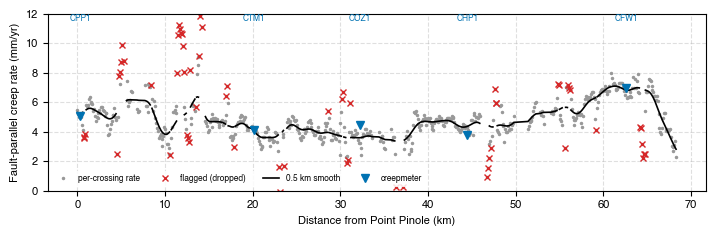

In [13]:
# [25]
km = km_of(lats)
fig, ax = plt.subplots(figsize=(7.2, 2.4))
ax.plot(km, fp_rate_raw, ".", color="0.6", ms=3, label="per-crossing rate")
ax.plot(km[landslide_flag], fp_rate_raw[landslide_flag], "x", color="tab:red", ms=4, label="flagged (dropped)")
ax.plot(km, fp_rate_smooth, "-", color="k", lw=1.2, label=f"{rate_smooth_km} km smooth")
for code, la, lo, name in creepmeters:
    ax.plot(km_of([la])[0], creepmeter_rate[code], "v", color="#0072B2", ms=6, label="creepmeter" if code == "CPP1" else None)
    ax.text(km_of([la])[0], 11.5, code, ha="center", fontsize=6, color="#0072B2")
ax.set_xlabel("Distance from Point Pinole (km)")
ax.set_ylabel("Fault-parallel creep rate (mm/yr)")
ax.set_ylim(0, 12)
ax.grid(True, ls="--", alpha=0.4)
ax.legend(fontsize=6, ncol=4)
fig.tight_layout()
f_qc = os.path.join(fig_dir, f"qc03_creep_rate_profile_{params}.png"); fig.savefig(f_qc, dpi=300); fig.savefig(f_qc.replace(".png", ".pdf"))
plt.show()

## [26] Figure S4: real versus interpolated epochs

Which track is measured and which is filled in at each epoch of the common
grid. Before both orbits reached 6-day sampling they shared few dates, so
nearly every early epoch has one track interpolated. The 6-day start dates and
the window when both were acquired on the same days are computed from the
acquisition lists, not assumed.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


common grid: 439 dates, Sep 2016 to Mar 2026
both orbits real       : 291 epochs
ascending interpolated : 83 (19%)
descending interpolated: 65 (15%)
acquisitions           : asc 359, desc 374
6-day sampling starts  : asc Oct 2018, desc Jun 2019
same-day window        : Mar 2020 -> Dec 2021 (2020.221-2021.98), 107 epochs, both real 99%, interpolated inside it: asc 1, desc 0
Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-30/figS_acquisitions_ap30-150m_coh0.7_mp5_sw200m_gap45d.png


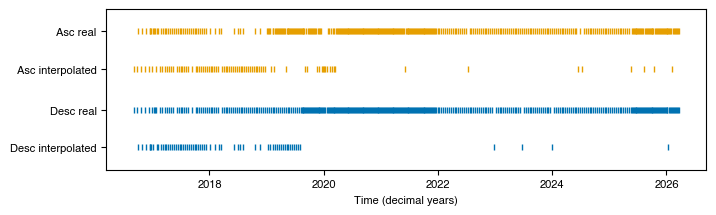

In [14]:
# [27]
def month_year(dec_year):
    return utils.decimal_year_to_date(dec_year).strftime("%b %Y")


def sixday_start(dates, max_days=8.0, window=10):
    """First date from which sampling is sustained ~6-day (rolling median interval <= max_days)."""
    gaps = np.diff(dates) * 365.25
    rolling = pd.Series(gaps).rolling(window, min_periods=window).median().to_numpy()
    ok = np.where(rolling <= max_days)[0]
    return dates[ok[0] - window + 1] if len(ok) else None


def main_interp_block_end(dates, is_real, quiet_days=180.0):
    """End of the main early run of interpolated epochs (a quiet stretch of quiet_days closes it)."""
    interp_dates = dates[~is_real]
    if len(interp_dates) == 0:
        return dates[0]
    breaks = np.where(np.diff(interp_dates) * 365.25 > quiet_days)[0]
    return interp_dates[breaks[0]] if len(breaks) else interp_dates[-1]


acq = {"asc": mask_stats["ascending"]["ts_dates"], "desc": mask_stats["descending"]["ts_dates"]}
sixday_asc, sixday_desc = sixday_start(acq["asc"]), sixday_start(acq["desc"])
window_start = max(sixday_asc, sixday_desc, main_interp_block_end(common_dates, real["asc"]),
                   main_interp_block_end(common_dates, real["desc"]))
window_start = float(common_dates[common_dates > window_start].min())
in_window = (common_dates >= window_start) & (common_dates <= s1b_death)

S4 = [f"common grid: {len(common_dates)} dates, {month_year(common_dates[0])} to {month_year(common_dates[-1])}",
      f"both orbits real       : {both_real.sum()} epochs",
      f"ascending interpolated : {(~real['asc']).sum()} ({100 * (~real['asc']).mean():.0f}%)",
      f"descending interpolated: {(~real['desc']).sum()} ({100 * (~real['desc']).mean():.0f}%)",
      f"acquisitions           : asc {acq['asc'].size}, desc {acq['desc'].size}",
      f"6-day sampling starts  : asc {month_year(sixday_asc)}, desc {month_year(sixday_desc)}",
      f"same-day window        : {month_year(window_start)} -> {month_year(s1b_death)} ({window_start:.3f}-{s1b_death:g}), "
      f"{in_window.sum()} epochs, both real {both_real[in_window].mean():.0%}, interpolated inside it: "
      f"asc {(~real['asc'])[in_window].sum()}, desc {(~real['desc'])[in_window].sum()}"]
print("\n".join(S4))

fig, ax = plt.subplots(figsize=(7.2, 2.2))
ax.plot(common_dates, real["asc"].astype(int) + 2.1, "|", ms=5, color="#E69F00")
ax.plot(common_dates, real["desc"].astype(int), "|", ms=5, color="#0072B2")
ax.set_yticks([0, 1, 2.1, 3.1])
ax.set_yticklabels(["Desc interpolated", "Desc real", "Asc interpolated", "Asc real"])
ax.set_ylim(-0.6, 3.7)
ax.set_xlabel("Time (decimal years)")
fig.tight_layout()
figS4 = os.path.join(fig_dir, f"figS_acquisitions_{params}_gap{max_interp_gap_days:.0f}d.png")
fig.savefig(figS4, dpi=300)
fig.savefig(figS4.replace(".png", ".pdf"))
print("Saved figure to:", figS4)
plt.show()

## [28] REGISTER

In [15]:
# [29]
lines = ["03 CROSS-FAULT CREEP TIME SERIES",
         f"aperture {dist_min * 1000:.0f}-{dist_max * 1000:.0f} m, along-strike +/-{x_width * 1000:.0f} m, "
         f"min {min_points} px/side, coherence {coh_timeseries}", ""]
for track, stats in mask_stats.items():
    lines.append(f"{track:<11} {stats['n_crossings']} crossings, {stats['n_dates']} dates; rate mask n={stats['n_px']} px, "
                 f"sigma {stats['sigma']:.3f} mm/yr, cut +/-{stats['rate_cut']:.3f}, rejected {stats['rej_pct']:.1f}%, "
                 f"max|dev| {stats['max_dev']:.1f}")
lines += ["", *S4, "",
          f"crossings analysed {len(fp_rate_raw)}, landslide-flagged {int(landslide_flag.sum())} (trend residual sigma {trend_sigma:.2f} mm/yr)",
          f"FP creep rate (raw, cleaned): n {valid.size}, median {np.median(valid):.2f}, 5-95% {np.percentile(valid, 5):.2f} to "
          f"{np.percentile(valid, 95):.2f}, min-max {valid.min():.2f} to {valid.max():.2f} mm/yr",
          f"FP creep rate (smoothed {rate_smooth_km} km): median {np.nanmedian(fp_rate_smooth):.2f}, "
          f"5-95% {np.nanpercentile(fp_rate_smooth, 5):.2f} to {np.nanpercentile(fp_rate_smooth, 95):.2f} mm/yr"]
sidecar = REG.sidecar("03_creep", lines)

for track, stats in mask_stats.items():
    tag = track[:3]
    REG.register(f"03_n_crossings_{tag}", stats["n_crossings"], "count", 0, where="M3", cell="extract", sidecar=sidecar)
    REG.register(f"03_n_acquisitions_{tag}", stats["n_dates"], "count", 0, where="M1, M3", cell="extract", sidecar=sidecar)
    REG.register(f"03_rate_mask_sigma_{tag}", stats["sigma"], "mm/yr", 2, where="M3, Fig S3", cell="extract", sidecar=sidecar)
    REG.register(f"03_rate_mask_cut_{tag}", stats["rate_cut"], "mm/yr", 2, where="M3, Fig S3", cell="extract", sidecar=sidecar)
    REG.register(f"03_rate_mask_rejected_pct_{tag}", stats["rej_pct"], "pct", 1, where="M3, Fig S3", cell="extract", sidecar=sidecar)
    REG.register(f"03_rate_mask_maxdev_{tag}", stats["max_dev"], "mm/yr", 1, where="M3, Fig S3", cell="extract", sidecar=sidecar)
REG.register("03_n_common_dates", len(common_dates), "count", 0, where="M3, Fig S4", cell="common-grid", sidecar=sidecar)
REG.register("03_n_both_real", int(both_real.sum()), "count", 0, where="M3, Fig S4", cell="common-grid", sidecar=sidecar)
REG.register("03_interp_pct_asc", 100 * (~real["asc"]).mean(), "pct", 0, where="M3, Fig S4", cell="common-grid", sidecar=sidecar)
REG.register("03_interp_pct_desc", 100 * (~real["desc"]).mean(), "pct", 0, where="M3, Fig S4", cell="common-grid", sidecar=sidecar)
REG.register("03_window_start", t0, "decyear", 3, where="M3", cell="common-grid", sidecar=sidecar)
REG.register("03_window_end", t1, "decyear", 3, where="M3", cell="common-grid", sidecar=sidecar)
REG.register("03_sixday_start_asc", month_year(sixday_asc), "date", 0, where="M3", cell="figS4", sidecar=sidecar)
REG.register("03_sixday_start_desc", month_year(sixday_desc), "date", 0, where="M3", cell="figS4", sidecar=sidecar)
REG.register("03_sameday_window_epochs", int(in_window.sum()), "count", 0, where="M3", cell="figS4", sidecar=sidecar)
REG.register("03_n_crossings_common", len(fp_rate_raw), "count", 0, where="M3", cell="decompose", sidecar=sidecar)
REG.register("03_n_landslide_flagged", int(landslide_flag.sum()), "count", 0, where="M3", cell="landslide-flag", sidecar=sidecar)
REG.register("03_landslide_flagged_pct", 100 * landslide_flag.mean(), "pct", 0, where="M3", cell="landslide-flag", sidecar=sidecar)
REG.register("03_rate_median_mm_yr", np.median(valid), "mm/yr", 2, where="Results", cell="rate-profile", sidecar=sidecar)
REG.register("03_rate_p5_mm_yr", np.percentile(valid, 5), "mm/yr", 2, where="Results", cell="rate-profile", sidecar=sidecar)
REG.register("03_rate_p95_mm_yr", np.percentile(valid, 95), "mm/yr", 2, where="Results", cell="rate-profile", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/03_creep_timeseries/03_creep_stats.txt
  registered 03_n_crossings_asc = 654 count  -> M3


  registered 03_n_acquisitions_asc = 359 count  -> M1, M3
  registered 03_rate_mask_sigma_asc = 0.55 mm/yr  -> M3, Fig S3
  registered 03_rate_mask_cut_asc = 1.66 mm/yr  -> M3, Fig S3


  registered 03_rate_mask_rejected_pct_asc = 6.2 pct  -> M3, Fig S3
  registered 03_rate_mask_maxdev_asc = 16.1 mm/yr  -> M3, Fig S3


  registered 03_n_crossings_des = 629 count  -> M3
  registered 03_n_acquisitions_des = 374 count  -> M1, M3
  registered 03_rate_mask_sigma_des = 0.56 mm/yr  -> M3, Fig S3


  registered 03_rate_mask_cut_des = 1.69 mm/yr  -> M3, Fig S3
  registered 03_rate_mask_rejected_pct_des = 5.4 pct  -> M3, Fig S3


  registered 03_rate_mask_maxdev_des = 17.0 mm/yr  -> M3, Fig S3
  registered 03_n_common_dates = 439 count  -> M3, Fig S4
  registered 03_n_both_real = 291 count  -> M3, Fig S4


... (4 outputs left out)

  registered 03_landslide_flagged_pct = 12 pct  -> M3
  registered 03_rate_median_mm_yr = 4.69 mm/yr  -> Results


  registered 03_rate_p5_mm_yr = 3.15 mm/yr  -> Results
  registered 03_rate_p95_mm_yr = 7.09 mm/yr  -> Results


Rendered registry to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt'